# Lab 1. Getting started with Python

**INFO-H-500 | 3 hours | Course link: introduction (vision, sensors, image representation)**

In this lab you learn to handle an image as a NumPy array and to open the two medical formats you will meet in the next labs (DICOM and NIfTI).

**Goals**
- Use a notebook, NumPy arrays and Matplotlib with confidence.
- Know what *shape*, *dtype*, *min* and *max* say about an image.
- Read one DICOM slice and one NIfTI volume.

**How to work**
- Run the cells from top to bottom.
- Cells with `# Your code here` are for you. Cells with `check(...)` tell you if you are on track. They are not graded.
- Answer the three questions in the markdown cells marked **Answer**.
- Keep the optional challenge for the end.

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data, io

def check(name, ok):
    print(('OK     ' if ok else 'CHECK  ') + name)

## Cheat sheet: Python in 5 minutes
Read this cell, run it and change a few values. Nothing to write here.

In [7]:
# lists, loops, functions
values = [3, 1, 4, 1, 5]
squares = [v ** 2 for v in values]
print(squares, len(squares))

def mean_of(xs):
    total = 0
    for x in xs:
        total += x
    return total / len(xs)

print(mean_of(values))

# NumPy arrays: same thing, without the loops
a = np.array(values)
print(a.mean(), a.max(), a[1:4], a[a > 2])

# a 2D array is an image: rows first, columns second
img = np.zeros((3, 4), dtype=np.uint8)
img[1, 2] = 255
print(img)

[9, 1, 16, 1, 25] 5
2.8
2.8 5 [1 4 1] [3 4 5]
[[  0   0   0   0]
 [  0   0 255   0]
 [  0   0   0   0]]


## Exercise 1. Arrays and indexing

An image is a NumPy array. Indexing is `a[row, column]`, and slicing is `a[r0:r1, c0:c1]`.

In [14]:
a = np.arange(12).reshape(3, 4)
print(a)
print('shape:', a.shape, ' dtype:', a.dtype)

# second row of a (one line)
row1 = a[1,:]
print(row1)
# last column of a (one line)
col_last = a[:,-1]
print(col_last)
# the 2x2 block in the top-left corner
block = a[0:2,0:2]
print(block)
# all the values of a that are larger than 6
big = a[a>6]
print(big)

check('row', np.array_equal(row1, [4, 5, 6, 7]))
check('column', np.array_equal(col_last, [3, 7, 11]))
check('block', np.array_equal(block, [[0, 1], [4, 5]]))
check('mask', np.array_equal(big, [7, 8, 9, 10, 11]))

[[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]
shape: (3, 4)  dtype: int64
[4 5 6 7]
[ 3  7 11]
[[0 1]
 [4 5]]
[ 7  8  9 10 11]
OK     row
OK     column
OK     block
OK     mask


Now the same tools on a real image: the *camera* image of scikit-image.

In [ ]:
camera = data.camera()

# print shape, dtype, min and max of the image
print(camera.shape)
print(camera.dtype)
print(camera.min())
print(camera.max())

# crop the 100x100 pixels at the top-left corner of the image
crop = camera[0:100,0:100]
# boolean mask of the dark pixels (value below 20) and the fraction of dark pixels

fraction_dark = np.sum(camera<20)/camera.size

print('fraction of dark pixels: %.3f' % fraction_dark)
check('crop shape', crop.shape == (100, 100))
check('dark fraction between 0.05 and 0.10', 0.05 < fraction_dark < 0.10)

(512, 512)
uint8
0
255
fraction of dark pixels: 0.076
OK     crop shape
OK     dark fraction between 0.05 and 0.10


## Exercise 2. Displaying images

By default, Matplotlib applies a colour map to a single-channel image.

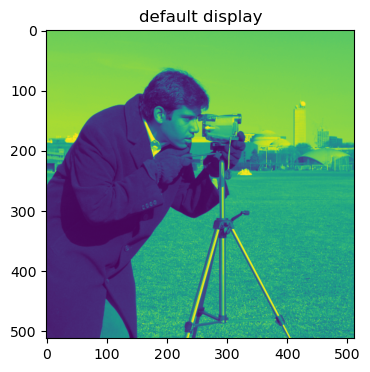

In [51]:
plt.figure(figsize=(4, 4))
plt.imshow(camera)
plt.title('default display')
plt.show()

**Answer 1.** Why does this gray image look coloured? Write one or two sentences.

Matplotlib applies a colour map to a single-channel image.

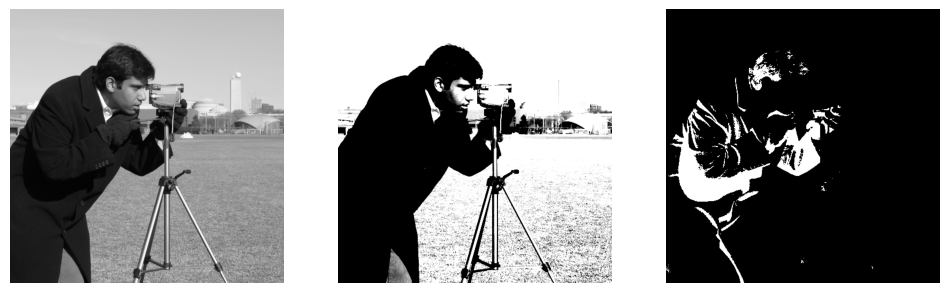

In [52]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

# left: gray display. Middle: gray display with vmin=100, vmax=150. Right: the dark mask of exercise 1
axes[0].imshow(camera, cmap='gray')

axes[1].imshow(camera, cmap='gray', vmin=100, vmax=150)

dark_mask = camera<20
axes[2].imshow(dark_mask, cmap = 'gray')

for ax in axes:
    ax.axis('off')
plt.show()

Now a colour image. It has a third dimension, the channels.

(512, 512, 3) uint8


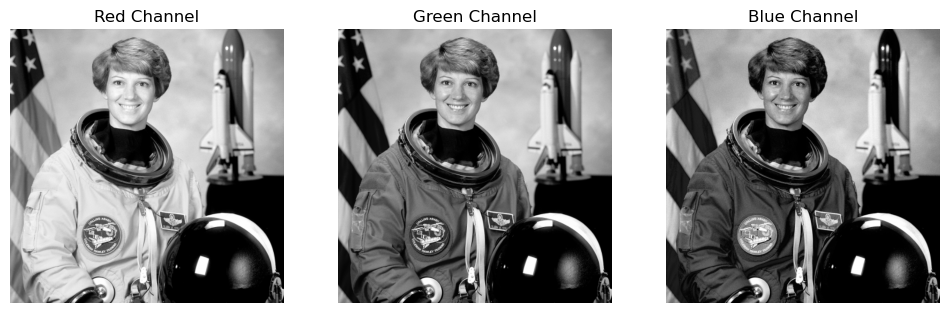

In [53]:
astronaut = data.astronaut()
print(astronaut.shape, astronaut.dtype)
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
# show the red, green and blue channels side by side (1 row, 3 columns) in gray, with a title for each
axes[0].imshow(astronaut[:,:,0], cmap='gray')
axes[0].set_title('Red Channel')

axes[1].imshow(astronaut[:,:,1], cmap='gray')
axes[1].set_title('Green Channel')

axes[2].imshow(astronaut[:,:,2], cmap='gray')
axes[2].set_title('Blue Channel')


for ax in axes:
    ax.axis('off')
plt.show()

**Answer 2.** What does the data type `uint8` mean? What happens to `np.uint8(250) + np.uint8(10)`? Try it.

It stands for unsigned 8-bit integer. 0 represents absolute black and 255 maximum brightness (full color intensity)

"RuntimeWarning: overflow encountered in scalar add
  print(np.uint8(250)+np.uint8(10))" There is overflow

**Answer 3.** What is the third dimension of a colour image? Which channel is bright on the red part of the image?

The third dimension of a color image represents the color channels. That third dimension stores the intensity values for each of those color components at every pixel.

The Red channel is bright on the red part of the image. In purely red areas, this channel will have high intensity values (closer to 255), while the green and blue channels will have low values (closer to 0).

In [ ]:
np.uint8(250)+np.uint8(10)

4


C:\Users\julia\AppData\Local\Temp\ipykernel_21992\1782241074.py:1: RuntimeWarning: overflow encountered in scalar add
  print(np.uint8(250)+np.uint8(10))


## Exercise 3. Reading and saving, DICOM and NIfTI

**3a. Standard files.** Save the camera image as PNG and as JPEG, read them back, and compare with the original.

In [56]:
from pathlib import Path

# Folder with the course data files (anatomical.nii, brodatz.pgm, ...), shared by all the labs
DATA = Path('../data')
print('data folder:', DATA.resolve())

data folder: C:\Users\julia\Downloads\Labs-20261104\data


In [58]:
import tempfile
tmp = Path(tempfile.mkdtemp())

# save camera as camera.png and camera.jpg in tmp (io.imsave), then read them back (io.imread)
io.imsave(tmp / 'camera.png', camera)
io.imsave(tmp / 'camera.jpg', camera)

png = io.imread(tmp / 'camera.png')
jpg = io.imread(tmp / 'camera.jpg')

check('PNG is identical to the original (lossless)', np.array_equal(png, camera))
check('JPEG is different from the original (lossy)', not np.array_equal(jpg, camera))
print('largest absolute difference with JPEG:', np.abs(jpg.astype(int) - camera.astype(int)).max())

OK     PNG is identical to the original (lossless)
OK     JPEG is different from the original (lossy)
largest absolute difference with JPEG: 34


**3b. DICOM.** A DICOM file holds a header (metadata) and the pixels. `pydicom` reads both.

In [ ]:
%pip install pydicom

In [70]:
import pydicom
from pydicom.data import get_testdata_file

ds = pydicom.dcmread(get_testdata_file('CT_small.dcm'))

# print five metadata fields of your choice, for example Modality, Rows, Columns, PixelSpacing, SliceThickness
print("Modality:", ds.Modality)
print("Rows (Filas):", ds.Rows)
print("Columns (Columnas):", ds.Columns)
print("Pixel Spacing:", ds.PixelSpacing)
print("Slice Thickness:", ds.SliceThickness)

ct = ds.pixel_array
print(ct.shape, ct.dtype, ct.min(), ct.max())

Modality: CT
Rows (Filas): 128
Columns (Columnas): 128
Pixel Spacing: [0.661468, 0.661468]
Slice Thickness: 5.000000
(128, 128) int16 128 2191


HU range: -896.0 1167.0


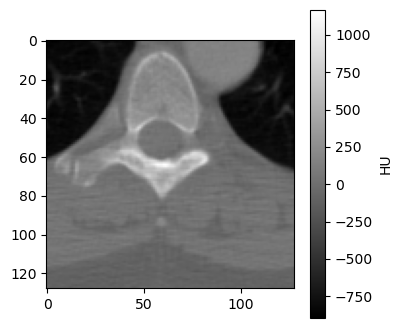

OK     the lowest value (air) is below -800 HU


In [72]:
# Hounsfield units (HU): the stored values are rescaled with a slope and an intercept
slope, intercept = float(ds.RescaleSlope), float(ds.RescaleIntercept)

# convert the stored values into HU
hu = ds.pixel_array * slope + intercept

print('HU range:', hu.min(), hu.max())
plt.figure(figsize=(4, 4))
plt.imshow(hu, cmap='gray')
plt.colorbar(label='HU')
plt.show()
check('the lowest value (air) is below -800 HU', hu.min() < -800)

**3c. NIfTI.** A NIfTI file holds a 3D volume. `nibabel` reads it.

In [74]:
%pip install nibabel

   ---------------------------------------- 0.0/3.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/3.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/3.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/3.3 MB ? eta -:--:--
   --- ------------------------------------ 0.3/3.3 MB ? eta -:--:--
   --- ------------------------------------ 0.3/3.3 MB ? eta -:--:--
   --- ------------------------------------ 0.3/3.3 MB ? eta -:--:--
   --- ------------------------------------ 0.3/3.3 MB ? eta -:--:--
   --- ------------------------------------ 0.3/3.3 MB ? eta -:--:--
   ------ --------------------------------- 0.5/3.3 MB 300.2 kB/s eta 0:00:10
   ------ --------------------------------- 0.5/3.3 MB 300.2 kB/s eta 0:00:10
   ------ --------------------------------- 0.5/3.3 MB 300.2 kB/s eta 0:00:10
   --------- ------------------------------ 0.8/3.3 MB 320.6 kB/s eta 0:00:08
   --------- ------------------------------ 0.8/3.3 MB 320.6 kB/s e

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


shape: (33, 41, 25)  voxel size (mm): (np.float32(2.0), np.float32(2.0), np.float32(2.0))


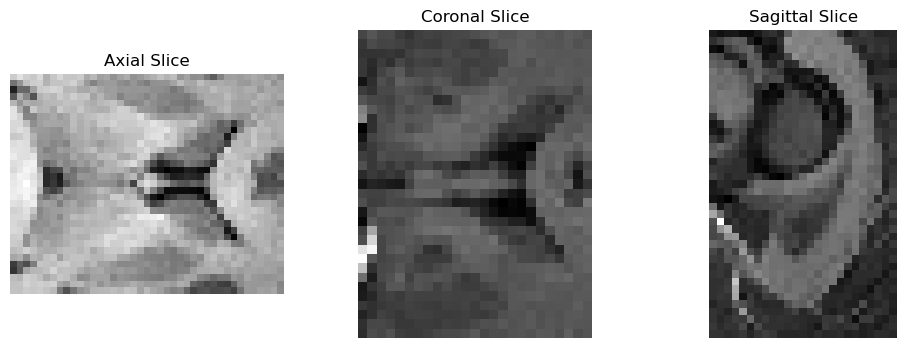

In [82]:
import nibabel as nib

vol_file = nib.load(DATA / 'anatomical.nii')
vol = vol_file.get_fdata()
print('shape:', vol.shape, ' voxel size (mm):', vol_file.header.get_zooms())

# show the central axial, coronal and sagittal slices side by side, by slicing vol along each axis
x,y,z = vol.shape

axial_slice = vol[:,:,z//2]
coronal_slice = vol[:,y//2,:]
sagittal_slice = vol[x//2,:,:]

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(axial_slice, cmap="gray")
axes[0].set_title('Axial Slice')
axes[1].imshow(coronal_slice, cmap="gray")
axes[1].set_title('Coronal Slice')
axes[2].imshow(sagittal_slice, cmap="gray")
axes[2].set_title('Sagittal Slice')

for ax in axes:
    ax.axis('off')
plt.show()


## Optional challenge

Look at the histogram of the CT slice in HU. Find the typical value of air and of bone, then display **only the bone** with a mask (set the other pixels to the minimum value).

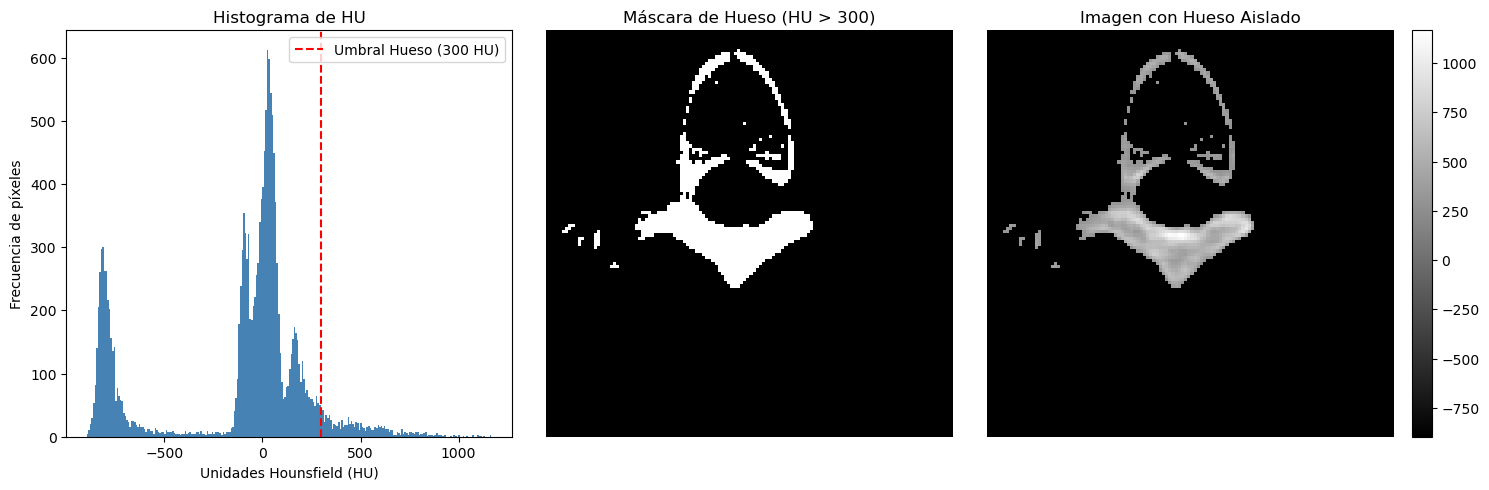

In [86]:
# histogram of hu, then a bone mask (threshold chosen from the histogram) and the masked image
threshold = 300
bone_mask = hu > threshold

# Crear la imagen enmascarada (el resto de píxeles toman el valor mínimo de la imagen)
masked_image = np.where(bone_mask, hu, hu.min())

# Configurar la visualización (3 columnas: Histograma, Máscara, Imagen aislada)
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# 1. Histograma de la imagen en HU
axes[0].hist(hu.ravel(), bins=256, color='steelblue', edgecolor='none')
axes[0].set_title('Histograma de HU')
axes[0].set_xlabel('Unidades Hounsfield (HU)')
axes[0].set_ylabel('Frecuencia de píxeles')
axes[0].axvline(threshold, color='red', linestyle='--', label=f'Umbral Hueso ({threshold} HU)')
axes[0].legend()

# 2. Máscara de hueso
axes[1].imshow(bone_mask, cmap='gray')
axes[1].set_title(f'Máscara de Hueso (HU > {threshold})')
axes[1].axis('off')

# 3. Imagen enmascarada (solo hueso)
im = axes[2].imshow(masked_image, cmap='gray')
axes[2].set_title('Imagen con Hueso Aislado')
axes[2].axis('off')
fig.colorbar(im, ax=axes[2], fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()

## To hand in
This notebook, completed, with the three answers written.